In [1]:
print('hi')

hi


In [2]:
import os
import json
import re
from typing import TypedDict, List, Any, Dict

from dotenv import load_dotenv

from langchain_cohere import CohereEmbeddings, ChatCohere
from langchain_classic.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_core.messages import HumanMessage, AIMessage

from langgraph.graph import StateGraph, START, END

# load enviroment variables

In [3]:
load_dotenv()

COHERE_API_KEY = os.getenv("COHERE_API_KEY")

if COHERE_API_KEY:
    print("Cohere API key loaded")
else:
    print("Cohere API key not found")

Cohere API key loaded


# load DB

In [ ]:
embedding = CohereEmbeddings(
    model="embed-v4.0",
    cohere_api_key=COHERE_API_KEY
)

FAISS_DB_PATH = "vector_db/faiss_policy_index"

vectorstore = FAISS.load_local(
    FAISS_DB_PATH,
    embeddings=embedding,
    allow_dangerous_deserialization=True
)

retriever = vectorstore.as_retriever(
    search_type="mmr",
    search_kwargs={
        "k": 5,
        "fetch_k": 20
    }
)

print("FAISS DB loaded successfully")

FAISS DB loaded successfully


# load llm

In [5]:
llm = ChatCohere(
    model="command-a-03-2025",
    cohere_api_key=COHERE_API_KEY,
    temperature=0.2
)

print("LLM loaded successfully")

LLM loaded successfully


# JSON OUTPUT HANDLE 

In [6]:
def extract_json(text: str) -> dict:
    try:
        return json.loads(text)
    except:
        pass

    match = re.search(r"\{.*\}", text, re.DOTALL)

    if match:
        try:
            return json.loads(match.group())
        except:
            return {}

    return {}

# docs formatted 

In [7]:
def format_docs_with_sources(docs: List[Document]) -> str:
    formatted_docs = []

    for i, doc in enumerate(docs, start=1):
        metadata = doc.metadata

        source_text = f"""
            [Source {i}]
            File: {metadata.get("file_name", "Unknown")}
            Page: {metadata.get("page_number", "Unknown")}
            Version: {metadata.get("version", "Unknown")}
            Effective Date: {metadata.get("effective_date", "Unknown")}
            Latest: {metadata.get("is_latest", "Unknown")}

            Content:
            {doc.page_content}
        """
        formatted_docs.append(source_text)

    return "\n\n".join(formatted_docs)

# graph state

In [8]:
class GraphState(TypedDict):
    question: str
    chat_history: list

    need_retrieval: bool
    clarification_needed: bool
    classification_reason: str

    rewritten_query: str
    retry_count: int

    retrieved_docs: List[Document]

    context_relevant: bool
    context_score: float
    context_reason: str

    version_conflict_found: bool
    latest_docs: List[Document]
    conflict_summary: str

    answer: str

    is_answer_supported: bool
    faithfulness_score: float
    unsupported_claims: List[str]

    final_answer: str

# LLM classifier helper

In [9]:
def llm_classify_query(question: str, has_chat_history: bool) -> dict:
    prompt = f"""
You are a query router for a corporate policy/SOP Self-RAG system.

Decide how to handle the user question.

Return ONLY valid JSON:
{{"need_retrieval": true/false, "clarification_needed": true/false, "reason": "short reason"}}

Rules:
- retrieval true: policy/SOP rules, reimbursement, claims, invoice, travel, leave, WFH, approval, documents, deployment, IT access, procurement, vendor, security, allowed/not allowed.
- clarification true: vague follow-up like "is this allowed", "what about this", "can I do that" when there is no chat history.
- retrieval false: greeting, general definition, small talk, assistant/project question, or non-policy question.
- If chat history exists, vague follow-up questions can use retrieval.

Examples:
"Hello" -> {{"need_retrieval": false, "clarification_needed": false, "reason": "greeting"}}
"What is SOP?" -> {{"need_retrieval": false, "clarification_needed": false, "reason": "general definition"}}
"Can I claim hotel bill?" -> {{"need_retrieval": true, "clarification_needed": false, "reason": "reimbursement policy"}}
"What documents are needed for this?" with chat history -> {{"need_retrieval": true, "clarification_needed": false, "reason": "follow-up policy context"}}
"Is this allowed?" without chat history -> {{"need_retrieval": false, "clarification_needed": true, "reason": "ambiguous follow-up without context"}}

Chat history exists: {has_chat_history}

Question:
{question}
"""

    response = llm.invoke(prompt)
    parsed = extract_json(response.content)

    return {
        "need_retrieval": parsed.get("need_retrieval", False),
        "clarification_needed": parsed.get("clarification_needed", False),
        "reason": parsed.get("reason", "llm fallback")
    }

In [10]:
def classify_query(state: GraphState) -> Dict[str, Any]:
    question = state["question"].strip()
    q = question.lower()
    chat_history = state.get("chat_history", [])
    has_chat_history = len(chat_history) > 0

    # Empty query
    if not q:
        return {
            "need_retrieval": False,
            "clarification_needed": True,
            "classification_reason": "empty query",
            "retry_count": state.get("retry_count", 0)
        }

    # 1. Clear no-retrieval cases
    no_retrieval_phrases = [
        "hi",
        "hello",
        "hey",
        "thanks",
        "thank you",
        "ok",
        "okay",
        "what is sop",
        "what is policy",
        "what is rag",
        "what is self rag",
        "explain sop",
        "meaning of sop",
        "who are you",
        "what can you do"
    ]

    if q in no_retrieval_phrases:
        return {
            "need_retrieval": False,
            "clarification_needed": False,
            "classification_reason": "rule: general/greeting query",
            "retry_count": state.get("retry_count", 0)
        }

    # 2. Ambiguous follow-up without memory
    ambiguous_patterns = [
        "is this allowed",
        "is that allowed",
        "is it allowed",
        "can i do this",
        "can i do that",
        "what about this",
        "what about that",
        "what about it",
        "is this possible",
        "is that possible",
        "what documents are needed for this",
        "what approval is needed for this",
        "is this reimbursable",
        "can i claim this"
    ]

    if any(pattern in q for pattern in ambiguous_patterns) and not has_chat_history:
        return {
            "need_retrieval": False,
            "clarification_needed": True,
            "classification_reason": "rule: ambiguous follow-up without chat history",
            "retry_count": state.get("retry_count", 0)
        }

    # 3. Clear policy/SOP retrieval cases
    retrieval_keywords = [
        "claim",
        "reimbursement",
        "reimbursable",
        "expense",
        "invoice",
        "gst",
        "bill",
        "hotel",
        "cab",
        "travel",
        "food",
        "leave",
        "notice period",
        "wfh",
        "work from home",
        "approval",
        "documents",
        "required document",
        "needed",
        "deploy",
        "deployment",
        "production",
        "friday",
        "access",
        "vpn",
        "jira",
        "git",
        "purchase",
        "procurement",
        "vendor",
        "security",
        "allowed",
        "not allowed",
        "can i",
        "am i allowed",
        "eligible",
        "eligibility",
        "limit",
        "policy",
        "sop"
    ]

    if any(keyword in q for keyword in retrieval_keywords):
        return {
            "need_retrieval": True,
            "clarification_needed": False,
            "classification_reason": "rule: policy/SOP keyword matched",
            "retry_count": state.get("retry_count", 0)
        }

    # 4. LLM fallback for unclear queries
    result = llm_classify_query(question, has_chat_history)

    return {
        "need_retrieval": result["need_retrieval"],
        "clarification_needed": result["clarification_needed"],
        "classification_reason": f"llm: {result['reason']}",
        "retry_count": state.get("retry_count", 0)
    }

# classification node

In [22]:
def clarification_response(state: GraphState) -> Dict[str, Any]:
    return {
        "final_answer": """
Please clarify what you are referring to.

Example:
- Is cab after 10 PM allowed?
- Is Friday production deployment allowed?
- Is leave during notice period allowed?
- Is this expense reimbursable?

Confidence: Low
""".strip()
    }

# Rewrite query using memory

In [23]:
def rewrite_query(state: GraphState) -> Dict[str, Any]:
    question = state["question"]
    chat_history = state.get("chat_history", [])

    if not chat_history:
        return {
            "rewritten_query": question
        }

    history_text = ""

    for msg in chat_history[-6:]:
        if isinstance(msg, HumanMessage):
            history_text += f"User: {msg.content}\n"
        elif isinstance(msg, AIMessage):
            history_text += f"Assistant: {msg.content}\n"

    prompt = f"""
        Rewrite the latest user question into a standalone search query for corporate policy/SOP PDF retrieval.

        Rules:
        - Use chat history only to resolve references like "this", "that", "it", "same".
        - Keep important terms: policy, SOP, reimbursement, approval, invoice, leave, deployment, access, procurement, security.
        - Do NOT answer.
        - Return only the rewritten query.

        Chat history:
        {history_text}

        Latest question:
        {question}
        """

    response = llm.invoke(prompt)

    return {
        "rewritten_query": response.content.strip()
    }

# Retry query rewrite

In [24]:
def rewrite_query_for_retry(state: GraphState) -> Dict[str, Any]:
    question = state["question"]
    previous_query = state.get("rewritten_query", question)
    context_reason = state.get("context_reason", "")
    retry_count = state.get("retry_count", 0)

    prompt = f"""
You are improving a failed search query for a corporate policy/SOP RAG system.

The previous retrieval was weak.

Original user question:
{question}

Previous search query:
{previous_query}

Reason context was weak:
{context_reason}

Rewrite the query to retrieve better policy/SOP documents.
Add useful keywords if relevant:
reimbursement, claim, approval, invoice, GST, leave, deployment, procurement, IT access, security, vendor, expense, travel.

Return only the improved search query.
"""

    response = llm.invoke(prompt)

    return {
        "rewritten_query": response.content.strip(),
        "retry_count": retry_count + 1
    }

# Retrieve documents

In [25]:
def retrieve_documents(state: GraphState) -> Dict[str, Any]:
    query = state.get("rewritten_query") or state["question"]

    docs = retriever.invoke(query)

    return {
        "retrieved_docs": docs
    }

# Grade context relevance

In [26]:
def grade_context(state: GraphState) -> Dict[str, Any]:
    question = state["question"]
    rewritten_query = state.get("rewritten_query", question)
    docs = state.get("retrieved_docs", [])

    context = format_docs_with_sources(docs)

    prompt = f"""
        You are a context relevance grader for a corporate policy RAG system.

        Check whether the retrieved context is relevant enough to answer the user question.

        User question:
        {question}

        Search query:
        {rewritten_query}

        Retrieved context:
        {context}

        Return ONLY valid JSON:
        {{"context_relevant": true/false, "score": 0.0, "reason": "short reason"}}

        Scoring:
        0.8-1.0 = clearly answers
        0.5-0.79 = partially useful
        below 0.5 = weak/irrelevant
    """

    response = llm.invoke(prompt)
    parsed = extract_json(response.content)

    return {
        "context_relevant": parsed.get("context_relevant", False),
        "context_score": float(parsed.get("score", 0.0)),
        "context_reason": parsed.get("reason", "")
    }

# Version and conflict checker

In [27]:
def check_version_conflict(state: GraphState) -> Dict[str, Any]:
    docs = state.get("retrieved_docs", [])

    doc_info = []

    for doc in docs:
        doc_info.append({
            "file_name": doc.metadata.get("file_name"),
            "version": doc.metadata.get("version"),
            "effective_date": doc.metadata.get("effective_date"),
            "is_latest": doc.metadata.get("is_latest"),
            "page_number": doc.metadata.get("page_number"),
            "content": doc.page_content[:1000]
        })

    prompt = f"""
        You are a corporate policy version and conflict checker.

        Check:
        1. Are there multiple versions of the same policy?
        2. Do old/new versions conflict?
        3. Which latest documents should be used?

        Retrieved documents:
        {json.dumps(doc_info, indent=2)}

        Return ONLY valid JSON:
        {{"version_conflict_found": true/false, "latest_doc_files": ["file.pdf"], "conflict_summary": "short summary"}}
        """

    response = llm.invoke(prompt)
    parsed = extract_json(response.content)

    latest_doc_files = set(parsed.get("latest_doc_files", []))

    latest_docs = []

    for doc in docs:
        file_name = doc.metadata.get("file_name")
        is_latest = doc.metadata.get("is_latest")

        if file_name in latest_doc_files or is_latest is True:
            latest_docs.append(doc)

    if not latest_docs:
        latest_docs = docs

    return {
        "version_conflict_found": parsed.get("version_conflict_found", False),
        "latest_docs": latest_docs,
        "conflict_summary": parsed.get("conflict_summary", "")
    }

# Generate answer

In [41]:
def generate_answer(state: GraphState) -> Dict[str, Any]:
    question = state["question"]
    docs = state.get("latest_docs") or state.get("retrieved_docs", [])
    conflict_summary = state.get("conflict_summary", "")
    context = format_docs_with_sources(docs)

    prompt = f"""
You are PolicyPilot AI, a careful corporate policy and SOP assistant.

Your task:
Answer the user question using ONLY the retrieved context.

Strict rules:
1. Do not invent rules, limits, dates, approvals, exceptions, or documents.
2. Use only facts clearly present in the retrieved context.
3. Prefer latest policy/SOP version when a version conflict exists.
4. If old and latest versions conflict, mention the latest version used.
5. If the question asks about an amount range like "above 50000" and the context has multiple slabs/ranges, show all applicable ranges. Do not collapse them into one approval.
6. If exact amount, location, document type, or condition is needed but missing, say what is missing and give conditional answer from the context.
7. If the context contains required documents, approvals, exceptions, or special checks, include them.
8. If the retrieved context is not enough, say exactly:
"I could not find a clear rule for this in the available policy documents."
9. Do not use outside knowledge.
10. Keep the answer concise but complete.

Reasoning instruction:
Before answering, internally check:
- Which retrieved source is most relevant?
- Is there any amount slab, limit, date, version, or exception?
- Does the answer exactly follow the retrieved rule?
- Are all claims supported by source text?

Conflict/version note:
{conflict_summary}

Retrieved context:
{context}

User question:
{question}

Return the answer in this format:

Direct Answer:
<clear answer. If conditional, say it clearly.>

Reason:
<brief explanation using only retrieved context.>

Required Documents / Approval:
<list documents, approvals, reviews, or say "Not specified in retrieved context".>

Sources:
- <file name>, Page <page>, Version <version>

Confidence:
High / Medium / Low
"""

    response = llm.invoke(prompt)

    return {
        "answer": response.content.strip()
    }

# Verify faithfulness

In [42]:
def verify_faithfulness(state: GraphState) -> Dict[str, Any]:
    question = state["question"]
    answer = state.get("answer", "")
    docs = state.get("latest_docs") or state.get("retrieved_docs", [])

    context = format_docs_with_sources(docs)

    prompt = f"""
        You are a faithfulness evaluator for a RAG system.

        Check if the answer is fully supported by the retrieved context.

        Question:
        {question}

        Retrieved context:
        {context}

        Answer:
        {answer}

        Return ONLY valid JSON:
        {{"is_answer_supported": true/false, "faithfulness_score": 0.0, "unsupported_claims": []}}

        Scoring:
        0.9-1.0 = fully supported
        0.7-0.89 = mostly supported
        0.5-0.69 = partially supported 
        below 0.5 = unsupported
    """

    response = llm.invoke(prompt)
    parsed = extract_json(response.content)

    return {
        "is_answer_supported": parsed.get("is_answer_supported", False),
        "faithfulness_score": float(parsed.get("faithfulness_score", 0.0)),
        "unsupported_claims": parsed.get("unsupported_claims", [])
    }

# Final response

In [43]:
def final_response(state: GraphState) -> Dict[str, Any]:
    if state.get("is_answer_supported", False):
        final_answer = state.get("answer", "")
    else:
        unsupported_claims = state.get("unsupported_claims", [])

        final_answer = f"""
            I could not generate a fully supported answer from the available policy documents.

            Reason:
            The faithfulness checker found that the answer may not be fully supported.

            Unsupported claims:
            {unsupported_claims}

            Please confirm with HR/Finance or upload the correct/latest policy document.

            Confidence: Low
            """

    return {
        "final_answer": final_answer.strip()
    }

# Direct answer node

In [44]:
def direct_answer(state: GraphState) -> Dict[str, Any]:
    question = state["question"]

    prompt = f"""
        Answer this general question briefly.
        Do not pretend to use policy documents.

        Question:
        {question}
    """

    response = llm.invoke(prompt)

    return {
        "final_answer": response.content.strip()
    }

# Poor context response node

In [45]:
def poor_context_response(state: GraphState) -> Dict[str, Any]:
    return {
        "final_answer": """
I could not find relevant information in the available policy/SOP documents even after retrying retrieval.

Please try rephrasing the question or upload the correct policy document.

Confidence: Low
""".strip()
    }

# Router functions

In [46]:
def route_after_classification(state: GraphState) -> str:
    if state.get("clarification_needed", False):
        return "clarification_response"

    if state.get("need_retrieval", True):
        return "rewrite_query"

    return "direct_answer"


def route_after_context_grading(state: GraphState) -> str:
    score = state.get("context_score", 0.0)
    retry_count = state.get("retry_count", 0)

    if score >= 0.5:
        return "check_version_conflict"

    if retry_count < 1:
        return "rewrite_query_for_retry"

    return "poor_context_response"

# Bulding SelF RAG graph

In [47]:
workflow = StateGraph(GraphState)

workflow.add_node("classify_query", classify_query)
workflow.add_node("rewrite_query", rewrite_query)
workflow.add_node("clarification_response", clarification_response)
workflow.add_node("rewrite_query_for_retry", rewrite_query_for_retry)
workflow.add_node("retrieve_documents", retrieve_documents)
workflow.add_node("grade_context", grade_context)
workflow.add_node("check_version_conflict", check_version_conflict)
workflow.add_node("generate_answer", generate_answer)
workflow.add_node("verify_faithfulness", verify_faithfulness)
workflow.add_node("final_response", final_response)

workflow.add_node("direct_answer", direct_answer)
workflow.add_node("poor_context_response", poor_context_response)

workflow.add_edge(START, "classify_query")

workflow.add_conditional_edges(
    "classify_query",
    route_after_classification,
    {
        "rewrite_query": "rewrite_query",
        "direct_answer": "direct_answer",
        "clarification_response": "clarification_response"
    }
)

workflow.add_edge("rewrite_query", "retrieve_documents")
workflow.add_edge("rewrite_query_for_retry", "retrieve_documents")
workflow.add_edge("retrieve_documents", "grade_context")

workflow.add_conditional_edges(
    "grade_context",
    route_after_context_grading,
    {
        "check_version_conflict": "check_version_conflict",
        "rewrite_query_for_retry": "rewrite_query_for_retry",
        "poor_context_response": "poor_context_response"
    }
)

workflow.add_edge("check_version_conflict", "generate_answer")
workflow.add_edge("generate_answer", "verify_faithfulness")
workflow.add_edge("verify_faithfulness", "final_response")

workflow.add_edge("direct_answer", END)
workflow.add_edge("clarification_response", END)
workflow.add_edge("poor_context_response", END)
workflow.add_edge("final_response", END)

self_rag_app = workflow.compile()

print("Self-RAG graph compiled successfully")

Self-RAG graph compiled successfully


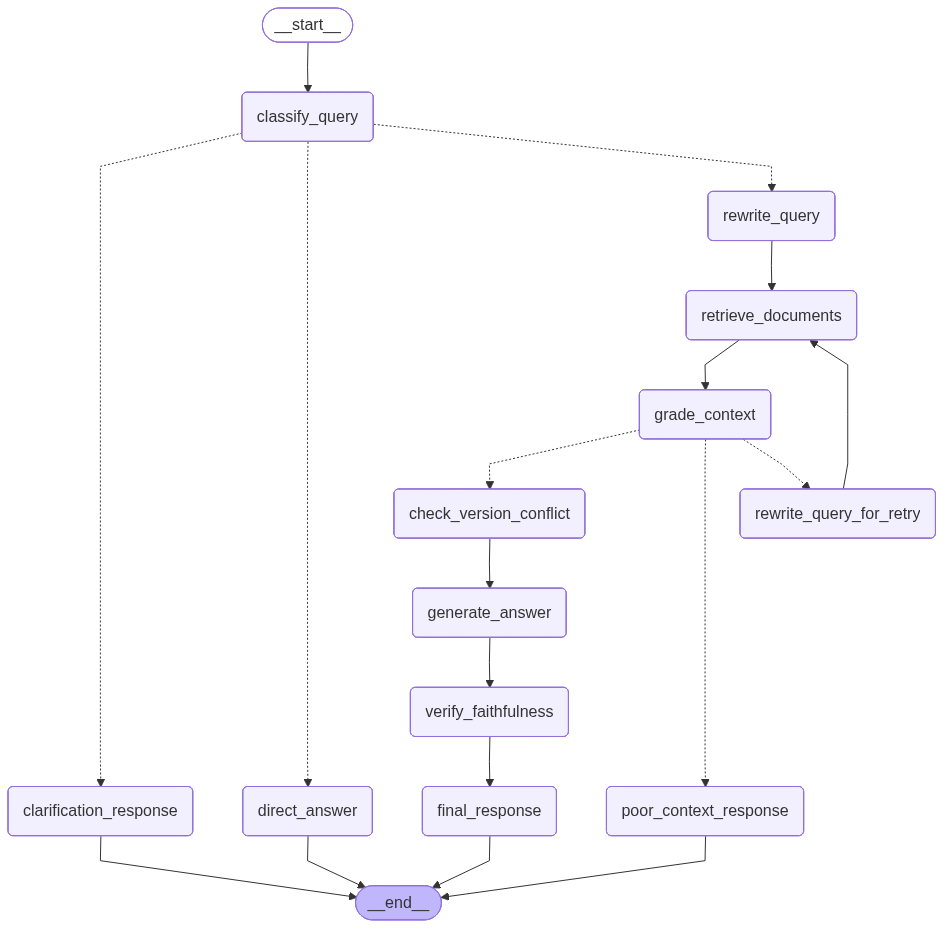

In [48]:
self_rag_app

# test -1 

In [49]:
result = self_rag_app.invoke({
    "question": "What approval is needed for software purchase above 50000?",
    "chat_history": [],
    "retry_count": 0
})

print(result["final_answer"])

Direct Answer:  
Department Head approval is required for software purchases between INR 25,001 and INR 100,000. Additionally, IT security review is mandatory for software purchases.

Reason:  
The approval matrix in the retrieved context specifies that purchases between INR 25,001 and INR 100,000 require Department Head approval. Furthermore, software purchases specifically require an IT security review before PO creation.

Required Documents / Approval:  
- Department Head approval  
- IT security review  
- Purchase request form  
- Business justification  
- Vendor quotation or sole-source note  
- Budget approval  
- Vendor onboarding confirmation  

Sources:  
- AceCorp_Procurement_SOP.pdf, Page 2, Version v1.0  

Confidence:  
High


In [39]:
print("Need Retrieval:", result.get("need_retrieval"))
print("Classification Reason:", result.get("classification_reason"))
print("Rewritten Query:", result.get("rewritten_query"))
print("Retry Count:", result.get("retry_count"))
print("Context Relevant:", result.get("context_relevant"))
print("Context Score:", result.get("context_score"))
print("Context Reason:", result.get("context_reason"))
print("Version Conflict Found:", result.get("version_conflict_found"))
print("Conflict Summary:", result.get("conflict_summary"))
print("Faithfulness Score:", result.get("faithfulness_score"))
print("Answer Supported:", result.get("is_answer_supported"))
print("Unsupported Claims:", result.get("unsupported_claims"))

Need Retrieval: True
Classification Reason: rule: policy/SOP keyword matched
Rewritten Query: What approval is needed for software purchase above 50000?
Retry Count: 0
Context Relevant: True
Context Score: 0.8
Context Reason: The retrieved context provides a clear approval matrix for software purchases, including the specific approval needed for purchases above INR 50,000 (Department Head), directly answering the user question.
Version Conflict Found: False
Conflict Summary: No version conflicts found. All documents are marked as the latest version with consistent effective dates. AceCorp_Procurement_SOP.pdf has multiple pages but no conflicting content across them.
Faithfulness Score: 0.5
Answer Supported: False
Unsupported Claims: ['Department Head and Procurement Head approval is required for software purchases above INR 50,000.']


In [40]:
for i, doc in enumerate(result.get("retrieved_docs", []), start=1):
    print("=" * 80)
    print("Source:", i)
    print("File:", doc.metadata.get("file_name"))
    print("Page:", doc.metadata.get("page_number"))
    print("Version:", doc.metadata.get("version"))
    print("Latest:", doc.metadata.get("is_latest"))
    print(doc.page_content[:500])

Source: 1
File: AceCorp_Procurement_SOP.pdf
Page: 2
Version: v1.0
Latest: True
AceCorp Internal Policy | FIN-SOP-PRC-016 | v1.0
Procurement Request and Purchase Order SOP
Internal Use Only - Fictional Demo Dataset - Page 2
Purchase Value
Approval Required
Up to INR 25000
Reporting Manager
INR 25001 to INR 100000
Department Head
INR 100001 to INR 500000
Department Head and Procurement Head
Above INR 500000
Business Unit Head and Finance Head
6. Required Documents
●
Purchase request form
●
Business justification
●
Vendor quotation or sole-source note
●
Budget approval
●
Secu
Source: 2
File: AceCorp_Procurement_SOP.pdf
Page: 2
Version: v1.0
Latest: True
Consulting service of INR 150000 requires three quotes or sole-source
justification.
Example 3
Employee confirms vendor by email before PO. This violates the SOP.
9. Frequently Asked Questions
Question
Answer
Can I purchase software directly with card?
No, software purchase requires IT security review and
approved PO unless exception exist

In [39]:
chat_history = []

q1 = "Can I claim 4200 hotel bill in Bangalore?"

r1 = self_rag_app.invoke({
    "question": q1,
    "chat_history": chat_history,
    "retry_count": 0
})

print(r1["final_answer"])

chat_history.extend([
    HumanMessage(content=q1),
    AIMessage(content=r1["final_answer"])
])

Direct Answer: Yes, you can claim a hotel bill of INR 4200 in Bangalore.

Reason: Bangalore is classified as a metro city, and the hotel reimbursement limit for metro cities is INR 4500 per night according to the policy. Since INR 4200 is within this limit, the claim is allowed.

Required Documents / Approval:  
- GST invoice for the hotel (if applicable).  
- Travel approval email.  
- Payment proof.  
- Reporting Manager approval (as the claim amount is up to INR 5000).  

Sources:  
- [Source 1, Page 2, Version v2.0](file: AceCorp_Travel_Policy_v2.pdf)  
- [Source 2, Page 2, Version v2.0](file: AceCorp_Travel_Policy_v2.pdf)  
- [Source 3, Page 1, Version v2.0](file: AceCorp_Travel_Policy_v2.pdf)  

Confidence: High


In [40]:
q2 = "What documents are needed for this?"

r2 = self_rag_app.invoke({
    "question": q2,
    "chat_history": chat_history,
    "retry_count": 0
})

print(r2["final_answer"])
print("Rewritten Query:", r2.get("rewritten_query"))
print("Retry Count:", r2.get("retry_count"))

Direct Answer:  
The required documents for travel and expense claims include:  
- Travel approval email  
- GST invoice for hotel (where applicable)  
- Cab or ride invoice  
- Payment proof  
- Client or business purpose note  
- Exception approval (if claim exceeds limit)  

Reason:  
These documents are explicitly listed in the **AceCorp Travel Policy v2.0** and **AceCorp Expense Reimbursement SOP v1.2** as mandatory for processing travel and expense claims.  

Required Documents / Approval:  
- Travel approval email  
- GST invoice (hotel)  
- Cab/ride invoice  
- Payment proof  
- Business purpose note  
- Exception approval (if applicable)  

Sources:  
[Source 1] AceCorp_Travel_Policy_v2.pdf, Page 2, Section 6  
[Source 2] AceCorp_Expense_Reimbursement_SOP.pdf, Page 2, Section 6  

Confidence: High
Rewritten Query: "AceCorp travel policy PDF documents required for hotel reimbursement claim approval"
Retry Count: 0


In [37]:
test_questions = [
    "Can I claim 4200 hotel bill in Bangalore?",
    "Can I claim cab fare after 10 PM?",
    "Can I deploy to production on Friday?",
    "Can I take leave during notice period?",
    "What approval is needed for software purchase above 50000?",
    "What is SOP?",
    "Is this allowed?"
]

for q in test_questions:
    print("=" * 100)
    print("Question:", q)

    result = self_rag_app.invoke({
        "question": q,
        "chat_history": [],
        "retry_count": 0
    })

    print(result["final_answer"])
    print("Classification:", result.get("classification_reason"))
    print("Retry Count:", result.get("retry_count"))
    print("Context Score:", result.get("context_score"))
    print("Faithfulness:", result.get("faithfulness_score"))

Question: Can I claim 4200 hotel bill in Bangalore?
Direct Answer: Yes, you can claim a hotel bill of INR 4200 in Bangalore.

Reason: Bangalore is classified as a metro city, and the hotel reimbursement limit for metro cities is INR 4500 per night as per the policy. Since INR 4200 is within this limit, the claim is allowed.

Required Documents / Approval:  
- GST invoice for the hotel (if applicable)  
- Travel approval email  
- Payment proof  
- Reporting Manager approval (as the claim amount is up to INR 5000)  

Sources:  
- [Source 1, Page 2, Version v2.0](file://AceCorp_Travel_Policy_v2.pdf)  
- [Source 2, Page 2, Version v2.0](file://AceCorp_Travel_Policy_v2.pdf)  
- [Source 3, Page 1, Version v2.0](file://AceCorp_Travel_Policy_v2.pdf)  

Confidence: High
Classification: rule: policy/SOP keyword matched
Retry Count: 0
Context Score: 0.85
Faithfulness: 0.95
Question: Can I claim cab fare after 10 PM?
Direct Answer: Yes, cab fare after 10 PM is reimbursable.

Reason: The policy ex

# TESTING - RAGAS

In [50]:
golden_tests = [
    {
        "question": "Can I claim 4200 hotel bill in Bangalore?",
        "expected_docs": ["AceCorp_Travel_Policy_v2.pdf", "AceCorp_Expense_Reimbursement_SOP.pdf"],
        "ground_truth": "Yes, if it is official travel and the hotel bill is within the metro city hotel limit with valid GST invoice and required approval."
    },
    {
        "question": "What approval is needed for software purchase above 50000?",
        "expected_docs": ["AceCorp_Procurement_SOP.pdf"],
        "ground_truth": "Approval depends on the amount: INR 50001 to INR 100000 requires Department Head approval; INR 100001 to INR 500000 requires Department Head and Procurement Head approval; above INR 500000 requires Business Unit Head and Finance Head approval. Software purchase also requires IT security review before PO creation."
    },
    {
        "question": "Can I deploy to production on Friday?",
        "expected_docs": ["AceCorp_Production_Deployment_SOP.pdf"],
        "ground_truth": "Regular production deployment on Friday is not allowed unless it is an emergency release with required approval."
    },
    {
        "question": "Can I claim cab fare after 10 PM?",
        "expected_docs": ["AceCorp_Travel_Policy_v2.pdf", "AceCorp_Expense_Reimbursement_SOP.pdf"],
        "ground_truth": "Cab fare after 10 PM is reimbursable if the ride invoice and required approval are provided."
    },
    {
        "question": "Can I take leave during notice period?",
        "expected_docs": ["AceCorp_Leave_Policy_2025.pdf"],
        "ground_truth": "Leave during notice period depends on the leave policy and requires the applicable approval."
    }
]

In [51]:
eval_rows = []

for test in golden_tests:
    result = self_rag_app.invoke({
        "question": test["question"],
        "chat_history": [],
        "retry_count": 0
    })

    docs = result.get("retrieved_docs", [])

    eval_rows.append({
        "question": test["question"],
        "answer": result.get("final_answer", ""),
        "contexts": [doc.page_content for doc in docs],
        "ground_truth": test["ground_truth"],
        "expected_docs": test["expected_docs"],
        "retrieved_files": [doc.metadata.get("file_name") for doc in docs],
        "context_score": result.get("context_score"),
        "faithfulness_score": result.get("faithfulness_score"),
        "retry_count": result.get("retry_count"),
    })

In [56]:
import pandas as pd

eval_df = pd.DataFrame(eval_rows)

def hit_rate(row):
    expected = set(row["expected_docs"])
    retrieved = set(row["retrieved_files"])
    return int(bool(expected.intersection(retrieved)))

def all_expected_found(row):
    expected = set(row["expected_docs"])
    retrieved = set(row["retrieved_files"])
    return int(expected.issubset(retrieved))

eval_df["hit_rate_at_5"] = eval_df.apply(hit_rate, axis=1)
eval_df["all_expected_found_at_5"] = eval_df.apply(all_expected_found, axis=1)

print("Hit Rate@5:", eval_df["hit_rate_at_5"].mean())
print("All Expected Found@5:", eval_df["all_expected_found_at_5"].mean())

eval_df

Hit Rate@5: 1.0
All Expected Found@5: 0.6


,question,answer,contexts,ground_truth,expected_docs,retrieved_files,context_score,faithfulness_score,retry_count,hit_rate_at_5,all_expected_found_at_5
0,Can I claim 4200 hotel bill in Bangalore?,"Direct Answer: \nYes, if other conditions are...",[reimbursable unless exception approval exists...,"Yes, if it is official travel and the hotel bi...","[AceCorp_Travel_Policy_v2.pdf, AceCorp_Expense...","[AceCorp_Travel_Policy_v2.pdf, AceCorp_Travel_...",0.9,0.95,0,1,0
1,What approval is needed for software purchase ...,Direct Answer: \nDepartment Head approval is ...,[AceCorp Internal Policy | FIN-SOP-PRC-016 | v...,Approval depends on the amount: INR 50001 to I...,[AceCorp_Procurement_SOP.pdf],"[AceCorp_Procurement_SOP.pdf, AceCorp_Procurem...",0.8,0.95,0,1,1
2,Can I deploy to production on Friday?,"Direct Answer: \nNo, deployments on Friday ar...",[Example 2\nSchema migration is planned. DBA a...,Regular production deployment on Friday is not...,[AceCorp_Production_Deployment_SOP.pdf],"[AceCorp_Production_Deployment_SOP.pdf, AceCor...",0.9,1.00,0,1,1
3,Can I claim cab fare after 10 PM?,"Direct Answer: \nYes, cab fare after 10 PM is...",[reimbursable unless exception approval exists...,Cab fare after 10 PM is reimbursable if the ri...,"[AceCorp_Travel_Policy_v2.pdf, AceCorp_Expense...","[AceCorp_Travel_Policy_v2.pdf, AceCorp_Travel_...",0.9,0.95,0,1,0
4,Can I take leave during notice period?,"Direct Answer: \nYes, but only with manager a...",[approval are required.\nExample 3\nEmployee t...,Leave during notice period depends on the leav...,[AceCorp_Leave_Policy_2025.pdf],"[AceCorp_Leave_Policy_2025.pdf, AceCorp_Leave_...",0.9,0.95,0,1,1
